In [5]:
import pandas as pd
import numpy as np
from pathlib import Path

In [6]:
arquivo = Path("dados_sensores_metaltech.csv")

In [7]:
if not arquivo.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {arquivo.resolve()}"
    )

In [8]:
df = pd.read_csv(arquivo)

print("Dataset carregado com sucesso!")
print(f"Quantidade de registros: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

Dataset carregado com sucesso!
Quantidade de registros: 10000
Quantidade de colunas: 6


In [9]:
display(df.head())

,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
0,2026-01-01 00:00:00,M03,67.015129,1.523088,40.672538,0
1,2026-01-01 00:01:00,M04,58.048478,2.738448,38.644490,0
2,2026-01-01 00:02:00,M01,67.938896,2.566715,46.814723,0
3,2026-01-01 00:03:00,M03,74.567369,3.174506,35.055251,0
4,2026-01-01 00:04:00,M03,72.688150,4.642862,42.926834,0


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      10000 non-null  str    
 1   id_maquina     10000 non-null  str    
 2   temperatura_c  9704 non-null   float64
 3   vibracao_mm_s  9701 non-null   float64
 4   pressao_bar    9700 non-null   float64
 5   falha_motor    10000 non-null  int64  
dtypes: float64(3), int64(1), str(2)
memory usage: 468.9 KB


In [11]:
print("\n Valores ausentes por coluna: ")
display(df.isnull().sum().to_frame(name='valores_ausentes'))



 Valores ausentes por coluna: 


,valores_ausentes
timestamp,0
id_maquina,0
temperatura_c,296
vibracao_mm_s,299
pressao_bar,300
falha_motor,0


In [12]:
print(f"\n Registros duplicados: {df.duplicated().sum()}")



 Registros duplicados: 0


In [15]:
diagnostico_nulos = pd.DataFrame({
    "valores_ausentes" : df.isnull().sum(),
    "percentual_ausente" : (df.isnull().mean() * 100).round(2)
})

In [17]:
display(diagnostico_nulos)

,valores_ausentes,percentual_ausente
timestamp,0,0.00
id_maquina,0,0.00
temperatura_c,296,2.96
vibracao_mm_s,299,2.99
pressao_bar,300,3.00
falha_motor,0,0.00


In [18]:
print("Valores encontrados em falha_motor:")
display(df["falha_motor"].value_counts(dropna=False).sort_index())

Valores encontrados em falha_motor:


falha_motor
0    9500
1     500
Name: count, dtype: int64

In [19]:
print("\nQuantidade de máquinas distintas:")
print(df["id_maquina"].nunique())


Quantidade de máquinas distintas:
4


In [20]:
print("\nPrimeiros timestamps:")
display(df["timestamp"].head(10))


Primeiros timestamps:


0    2026-01-01 00:00:00
1    2026-01-01 00:01:00
2    2026-01-01 00:02:00
3    2026-01-01 00:03:00
4    2026-01-01 00:04:00
5    2026-01-01 00:05:00
6    2026-01-01 00:06:00
7    2026-01-01 00:07:00
8    2026-01-01 00:08:00
9    2026-01-01 00:09:00
Name: timestamp, dtype: str

In [21]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Timestamps inválidos:", df["timestamp"].isna().sum())

print(
    "Registros fora de ordem cronológica:",
    (df["timestamp"].diff().dropna() < pd.Timedelta(0)).sum()
)

print(
    "Timestamps duplicados:",
    df["timestamp"].duplicated().sum()
)

display(df[["timestamp", "id_maquina"]].head(10))


Timestamps inválidos: 0
Registros fora de ordem cronológica: 0
Timestamps duplicados: 0


,timestamp,id_maquina
0,2026-01-01 00:00:00,M03
1,2026-01-01 00:01:00,M04
2,2026-01-01 00:02:00,M01
3,2026-01-01 00:03:00,M03
4,2026-01-01 00:04:00,M03
5,2026-01-01 00:05:00,M04
6,2026-01-01 00:06:00,M01
7,2026-01-01 00:07:00,M01
8,2026-01-01 00:08:00,M03
9,2026-01-01 00:09:00,M02


In [22]:
df_limpo = df.copy()

df_limpo = df_limpo.sort_values(
    by=["id_maquina", "timestamp"]
).reset_index(drop=True)

print("Dados ordenados por máquina e timestamp.")
display(df_limpo.head())


Dados ordenados por máquina e timestamp.


,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
0,2026-01-01 00:02:00,M01,67.938896,2.566715,46.814723,0
1,2026-01-01 00:06:00,M01,68.600033,4.367980,42.355141,0
2,2026-01-01 00:07:00,M01,63.604846,3.284385,40.326861,0
3,2026-01-01 00:15:00,M01,NaN,3.412334,36.503412,0
4,2026-01-01 00:21:00,M01,73.844198,3.040572,NaN,0


In [26]:

sensores = [
    "temperatura_c",
    "vibracao_mm_s",
    "pressao_bar"
]

for coluna in sensores:
    df_limpo[coluna] = (
        df_limpo.groupby("id_maquina")[coluna]
        .transform(
            lambda serie: serie.interpolate(
                method="linear",
                limit_area="inside"
            )
        )
    )

print("Valores ausentes após a interpolação:")
display(
    df_limpo[sensores]
    .isnull()
    .sum()
    .to_frame(name="valores_ausentes")
)


Valores ausentes após a interpolação:


,valores_ausentes
temperatura_c,0
vibracao_mm_s,0
pressao_bar,0


In [27]:
display(df_limpo[sensores].describe().T)

for coluna in sensores:
    print(f"\n{coluna}")
    print("5 menores valores:")
    display(df_limpo[coluna].nsmallest(5))

    print("5 maiores valores:")
    display(df_limpo[coluna].nlargest(5))


,count,mean,std,min,25%,50%,75%,max
temperatura_c,10000.0,81.032217,93.034542,50.387999,66.859274,70.345222,74.088231,999.900000
vibracao_mm_s,10000.0,2.920697,5.767929,-50.000000,2.670221,3.025688,3.401842,21.386227
pressao_bar,10000.0,41.677647,8.160043,26.603188,38.056100,40.210445,42.364904,102.177445



temperatura_c
5 menores valores:


3971    50.387999
6038    50.816722
8410    51.558174
3476    51.994574
4318    53.122104
Name: temperatura_c, dtype: float64

5 maiores valores:


711     999.9
773     999.9
926     999.9
1033    999.9
1089    999.9
Name: temperatura_c, dtype: float64

...

8962    21.386227
3049    20.482661
9697    19.854659
5689    19.784832
6203    19.708200
Name: vibracao_mm_s, dtype: float64


pressao_bar
5 menores valores:


2185    26.603188
1631    29.401545
5183    29.514864
3742    29.639938
2468    29.691813
Name: pressao_bar, dtype: float64

5 maiores valores:


3793    102.177445
9573     96.104225
4420     95.955494
3944     92.047276
5343     91.265533
Name: pressao_bar, dtype: float64

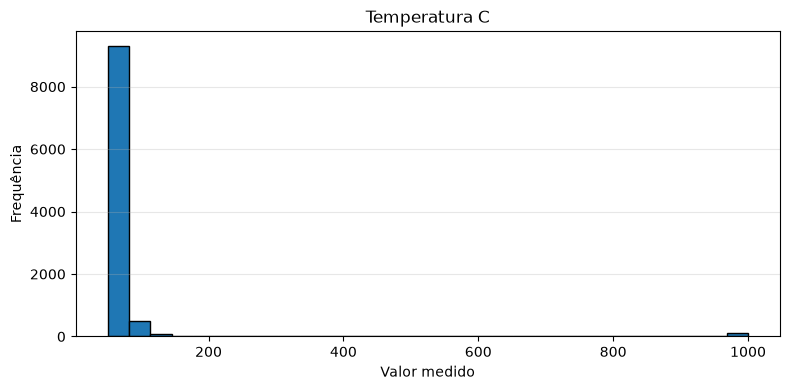

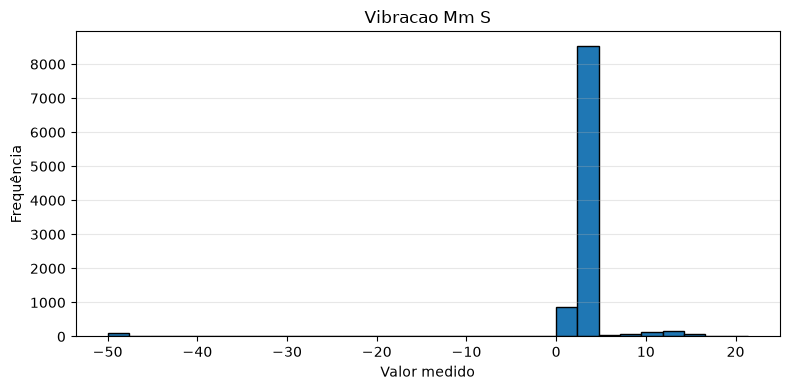

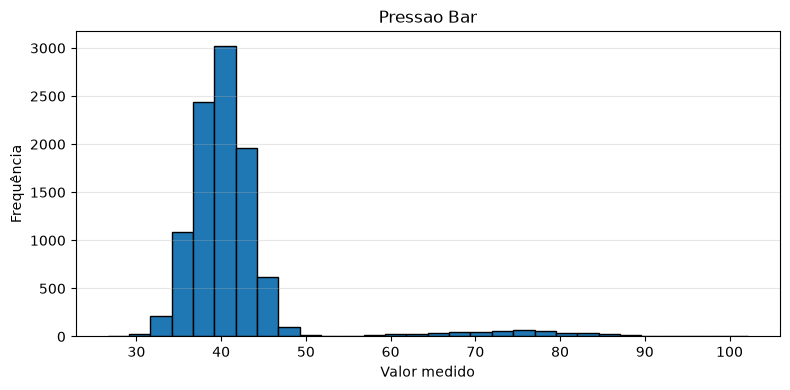

In [30]:

import matplotlib.pyplot as plt

for coluna in sensores:
    plt.figure(figsize=(8, 4))
    plt.hist(df_limpo[coluna].dropna(), bins=30, edgecolor="black")
    plt.title(coluna.replace("_", " ").title())
    plt.xlabel("Valor medido")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [31]:
display(df_limpo[sensores].describe().T)

print("Temperaturas iguais ou superiores a 999 °C:")
display(df_limpo[df_limpo["temperatura_c"] >= 999])

print("Vibrações negativas:")
display(df_limpo[df_limpo["vibracao_mm_s"] < 0])


,count,mean,std,min,25%,50%,75%,max
temperatura_c,10000.0,81.032217,93.034542,50.387999,66.859274,70.345222,74.088231,999.900000
vibracao_mm_s,10000.0,2.920697,5.767929,-50.000000,2.670221,3.025688,3.401842,21.386227
pressao_bar,10000.0,41.677647,8.160043,26.603188,38.056100,40.210445,42.364904,102.177445


Temperaturas iguais ou superiores a 999 °C:


,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
711,2026-01-02 21:47:00,M01,999.9,3.260433,37.667657,0
773,2026-01-03 01:19:00,M01,999.9,2.890471,37.814510,0
926,2026-01-03 11:10:00,M01,999.9,3.191066,41.489807,0
1033,2026-01-03 18:27:00,M01,999.9,2.760652,41.315639,0
1089,2026-01-03 22:39:00,M01,999.9,3.624911,35.437917,0
...,...,...,...,...,...,...
9265,2026-01-05 21:45:00,M04,999.9,2.536969,39.793435,0
9469,2026-01-06 10:28:00,M04,999.9,3.851054,34.639127,0
9936,2026-01-07 19:11:00,M04,999.9,3.027895,40.555944,0
9953,2026-01-07 20:07:00,M04,999.9,3.046031,37.691294,0


Vibrações negativas:


,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
45,2026-01-01 03:18:00,M01,73.094431,-50.0,39.898348,0
77,2026-01-01 05:17:00,M01,65.561152,-50.0,43.277502,0
81,2026-01-01 05:36:00,M01,69.659383,-50.0,35.821202,0
227,2026-01-01 14:46:00,M01,74.617543,-50.0,42.984079,0
476,2026-01-02 06:39:00,M01,66.577541,-50.0,45.014835,0
...,...,...,...,...,...,...
9244,2026-01-05 20:36:00,M04,57.538052,-50.0,36.303446,0
9269,2026-01-05 21:53:00,M04,70.382590,-50.0,42.647894,0
9714,2026-01-07 02:42:00,M04,71.533485,-50.0,37.025309,0
9813,2026-01-07 09:37:00,M04,75.761253,-50.0,38.992970,0


In [32]:
temperaturas_suspeitas = df_limpo["temperatura_c"] >= 999
vibracoes_negativas = df_limpo["vibracao_mm_s"] < 0

print("Temperaturas suspeitas:", temperaturas_suspeitas.sum())
print("Vibrações negativas:", vibracoes_negativas.sum())

df_limpo.loc[temperaturas_suspeitas, "temperatura_c"] = np.nan
df_limpo.loc[vibracoes_negativas, "vibracao_mm_s"] = np.nan

display(df_limpo[sensores].isnull().sum().to_frame(
    name="valores_ausentes"
))


Temperaturas suspeitas: 100
Vibrações negativas: 104


,valores_ausentes
temperatura_c,100
vibracao_mm_s,104
pressao_bar,0


In [33]:
print("Dimensões do dataset:", df_limpo.shape)

print("\nValores mínimos após o tratamento:")
display(df_limpo[sensores].min())

print("\nValores máximos após o tratamento:")
display(df_limpo[sensores].max())


Dimensões do dataset: (10000, 6)

Valores mínimos após o tratamento:


temperatura_c    50.387999
vibracao_mm_s     1.071812
pressao_bar      26.603188
dtype: float64


Valores máximos após o tratamento:


temperatura_c    536.027557
vibracao_mm_s     21.386227
pressao_bar      102.177445
dtype: float64

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp      10000 non-null  datetime64[us]
 1   id_maquina     10000 non-null  str           
 2   temperatura_c  9704 non-null   float64       
 3   vibracao_mm_s  9701 non-null   float64       
 4   pressao_bar    9700 non-null   float64       
 5   falha_motor    10000 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(1), str(1)
memory usage: 468.9 KB


In [35]:
print("Dimensões:", df_limpo.shape)

print("\nValores mínimos:")
display(df_limpo[sensores].min())

print("\nValores máximos:")
display(df_limpo[sensores].max())

print("\nValores ausentes:")
display(df_limpo[sensores].isnull().sum())


Dimensões: (10000, 6)

Valores mínimos:


temperatura_c    50.387999
vibracao_mm_s     1.071812
pressao_bar      26.603188
dtype: float64


Valores máximos:


temperatura_c    536.027557
vibracao_mm_s     21.386227
pressao_bar      102.177445
dtype: float64


Valores ausentes:


temperatura_c    100
vibracao_mm_s    104
pressao_bar        0
dtype: int64

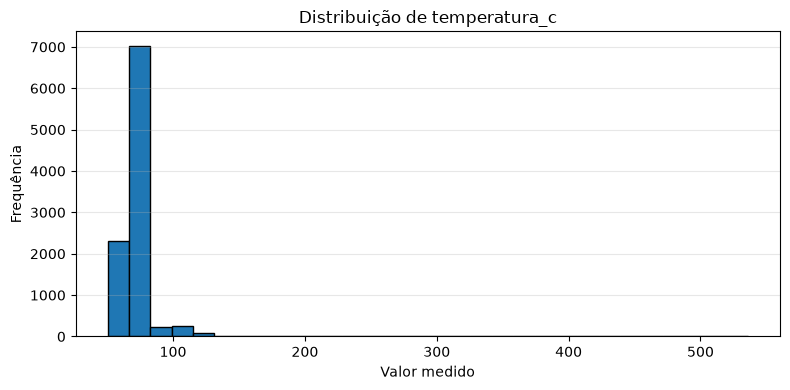

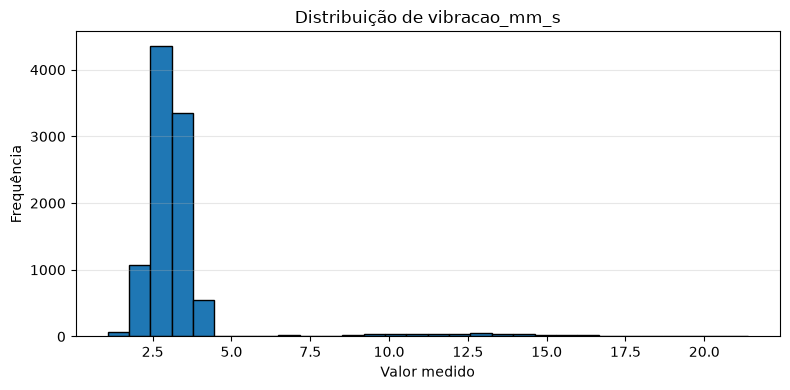

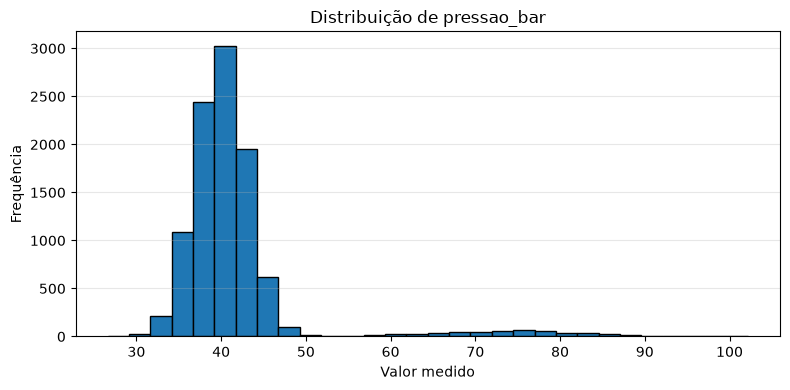

In [36]:
import matplotlib.pyplot as plt

for coluna in sensores:
    plt.figure(figsize=(8, 4))
    plt.hist(df_limpo[coluna].dropna(), bins=30, edgecolor="black")
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel("Valor medido")
    plt.ylabel("Frequência")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


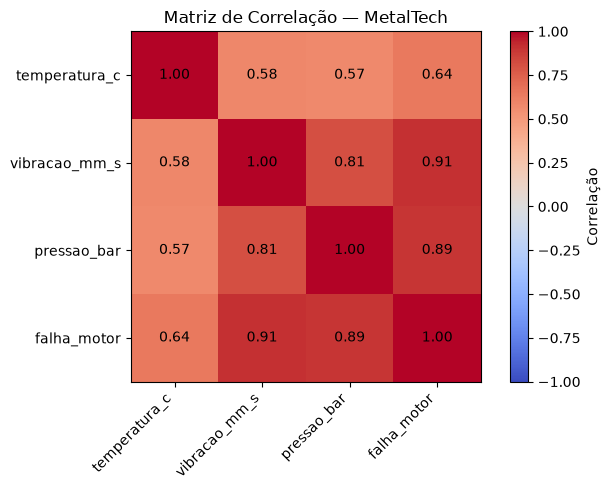

In [37]:
colunas_correlacao = sensores + ["falha_motor"]

correlacao = df_limpo[colunas_correlacao].corr()

plt.figure(figsize=(7, 5))
plt.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlação")
plt.xticks(range(len(colunas_correlacao)), colunas_correlacao,
           rotation=45, ha="right")
plt.yticks(range(len(colunas_correlacao)), colunas_correlacao)

for i in range(len(colunas_correlacao)):
    for j in range(len(colunas_correlacao)):
        valor = correlacao.iloc[i, j]
        plt.text(j, i, f"{valor:.2f}", ha="center", va="center")

plt.title("Matriz de Correlação — MetalTech")
plt.tight_layout()
plt.show()


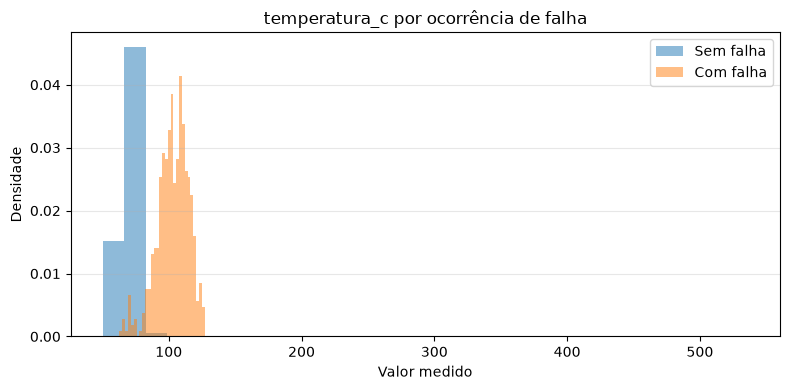

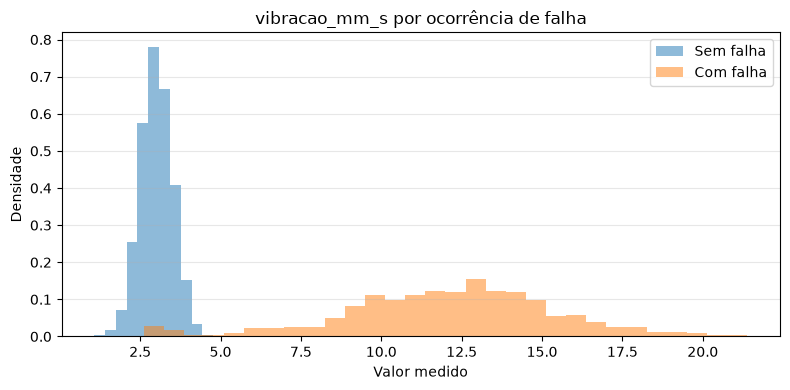

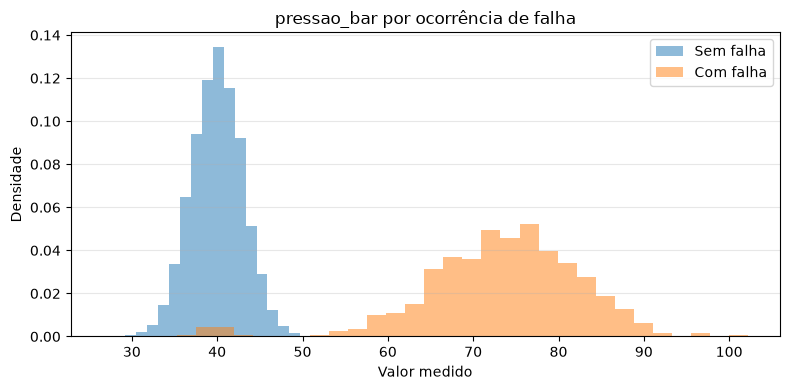

In [38]:
for coluna in sensores:
    plt.figure(figsize=(8, 4))

    for falha, rotulo in [(0, "Sem falha"), (1, "Com falha")]:
        dados = df_limpo.loc[
            df_limpo["falha_motor"] == falha, coluna
        ].dropna()

        plt.hist(
            dados,
            bins=30,
            alpha=0.5,
            density=True,
            label=rotulo
        )

    plt.title(f"{coluna} por ocorrência de falha")
    plt.xlabel("Valor medido")
    plt.ylabel("Densidade")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


In [39]:
resumo = pd.DataFrame({
    "tipo": df_limpo.dtypes.astype(str),
    "valores_ausentes": df_limpo.isnull().sum(),
    "percentual_ausente": (df_limpo.isnull().mean() * 100).round(2),
    "valores_distintos": df_limpo.nunique()
})

display(resumo)

print("Total de registros:", len(df_limpo))
print("Total de máquinas:", df_limpo["id_maquina"].nunique())
print("Registros com falha:", (df_limpo["falha_motor"] == 1).sum())
print("Registros sem falha:", (df_limpo["falha_motor"] == 0).sum())


,tipo,valores_ausentes,percentual_ausente,valores_distintos
timestamp,datetime64[us],0,0.00,10000
id_maquina,str,0,0.00,4
temperatura_c,float64,100,1.00,9900
vibracao_mm_s,float64,104,1.04,9896
pressao_bar,float64,0,0.00,10000
falha_motor,int64,0,0.00,2


Total de registros: 10000
Total de máquinas: 4
Registros com falha: 500
Registros sem falha: 9500


In [40]:
from pathlib import Path

pasta_dados = Path("data")
pasta_dados.mkdir(exist_ok=True)

arquivo_saida = pasta_dados / "dados_sensores_metaltech_tratados.csv"

df_limpo.to_csv(arquivo_saida, index=False)

print(f"Dataset salvo em: {arquivo_saida.resolve()}")


Dataset salvo em: C:\Users\ryhan_Schutz.EDU_FIESC\Documents\atividades_fabiano\atividade_pratica_doit_15_10\data\dados_sensores_metaltech_tratados.csv


2.1 — Preparação dos dados

In [41]:
X = df_limpo[
    ["temperatura_c", "vibracao_mm_s", "pressao_bar"]
]

y = df_limpo["falha_motor"]

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

print("\nDistribuição da variável alvo:")
display(y.value_counts().sort_index())


Dimensão de X: (10000, 3)
Dimensão de y: (10000,)

Distribuição da variável alvo:


falha_motor
0    9500
1     500
Name: count, dtype: int64

In [50]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Registros para treino:", len(X_treino))
print("Registros para teste:", len(X_teste))

print("\nFalhas no treino:")
display(y_treino.value_counts().sort_index())

print("\nFalhas no teste:")
display(y_teste.value_counts().sort_index())


Registros para treino: 7000
Registros para teste: 3000

Falhas no treino:


falha_motor
0    6650
1     350
Name: count, dtype: int64


Falhas no teste:


falha_motor
0    2850
1     150
Name: count, dtype: int64

In [51]:
print("Valores ausentes no treino:")
display(X_treino.isnull().sum())

print("\nValores ausentes no teste:")
display(X_teste.isnull().sum())


Valores ausentes no treino:


temperatura_c    66
vibracao_mm_s    80
pressao_bar       0
dtype: int64


Valores ausentes no teste:


temperatura_c    34
vibracao_mm_s    24
pressao_bar       0
dtype: int64

Primeiro modelo: Regressão Logística

In [52]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo_logistico = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("escalonamento", StandardScaler()),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

modelo_logistico.fit(X_treino, y_treino)

print("Modelo de Regressão Logística treinado com sucesso!")


Modelo de Regressão Logística treinado com sucesso!


In [53]:
y_pred_logistico = modelo_logistico.predict(X_teste)

print("Quantidade de previsões:", len(y_pred_logistico))
print("Falhas previstas:", (y_pred_logistico == 1).sum())
print("Operações normais previstas:", (y_pred_logistico == 0).sum())


Quantidade de previsões: 3000
Falhas previstas: 157
Operações normais previstas: 2843


Acurácia: 0.9977
Precisão: 0.9554
Recall: 1.0
F1-score: 0.9772

Relatório de classificação:
              precision    recall  f1-score   support

   Sem falha       1.00      1.00      1.00      2850
   Com falha       0.96      1.00      0.98       150

    accuracy                           1.00      3000
   macro avg       0.98      1.00      0.99      3000
weighted avg       1.00      1.00      1.00      3000



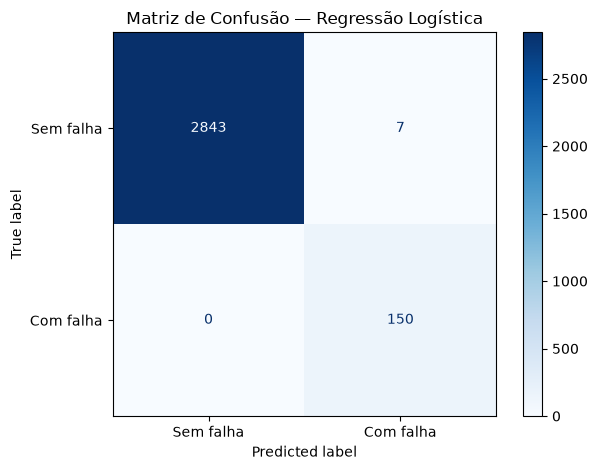

In [54]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Acurácia:", round(accuracy_score(y_teste, y_pred_logistico), 4))
print("Precisão:", round(precision_score(y_teste, y_pred_logistico, zero_division=0), 4))
print("Recall:", round(recall_score(y_teste, y_pred_logistico, zero_division=0), 4))
print("F1-score:", round(f1_score(y_teste, y_pred_logistico, zero_division=0), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    y_pred_logistico,
    target_names=["Sem falha", "Com falha"],
    zero_division=0
))

matriz = confusion_matrix(y_teste, y_pred_logistico)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sem falha", "Com falha"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de Confusão — Regressão Logística")
plt.tight_layout()
plt.show()


Primeiro modelo: Regressão Logística

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modelo_logistico = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("escalonamento", StandardScaler()),
    ("modelo", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

modelo_logistico.fit(X_treino, y_treino)

print("Modelo de Regressão Logística treinado com sucesso!")


Modelo de Regressão Logística treinado com sucesso!


In [56]:
y_pred_logistico = modelo_logistico.predict(X_teste)

print("Quantidade de previsões:", len(y_pred_logistico))
print("Falhas previstas:", (y_pred_logistico == 1).sum())
print("Operações normais previstas:", (y_pred_logistico == 0).sum())


Quantidade de previsões: 3000
Falhas previstas: 157
Operações normais previstas: 2843


Acurácia: 0.9977
Precisão: 0.9554
Recall: 1.0
F1-score: 0.9772

Relatório de classificação:
              precision    recall  f1-score   support

   Sem falha       1.00      1.00      1.00      2850
   Com falha       0.96      1.00      0.98       150

    accuracy                           1.00      3000
   macro avg       0.98      1.00      0.99      3000
weighted avg       1.00      1.00      1.00      3000



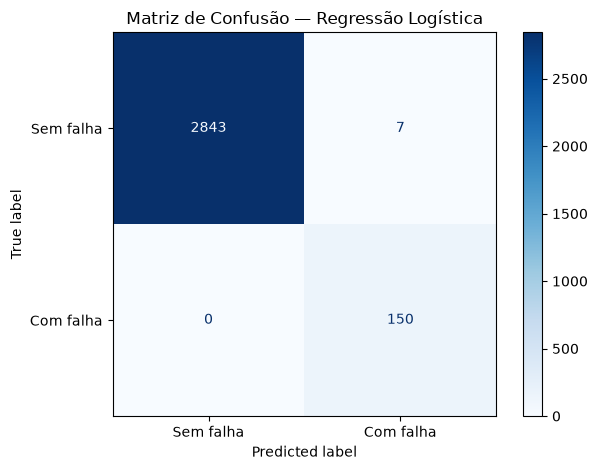

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Acurácia:", round(accuracy_score(y_teste, y_pred_logistico), 4))
print("Precisão:", round(precision_score(y_teste, y_pred_logistico, zero_division=0), 4))
print("Recall:", round(recall_score(y_teste, y_pred_logistico, zero_division=0), 4))
print("F1-score:", round(f1_score(y_teste, y_pred_logistico, zero_division=0), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    y_pred_logistico,
    target_names=["Sem falha", "Com falha"],
    zero_division=0
))

matriz = confusion_matrix(y_teste, y_pred_logistico)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sem falha", "Com falha"]
).plot(cmap="Blues", values_format="d")

plt.title("Matriz de Confusão — Regressão Logística")
plt.tight_layout()
plt.show()


In [58]:
from sklearn.ensemble import RandomForestClassifier

modelo_floresta = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_floresta.fit(X_treino, y_treino)

print("Random Forest treinada com sucesso!")


Random Forest treinada com sucesso!


Acurácia: 0.9997
Precisão: 0.9934
Recall: 1.0
F1-score: 0.9967

Relatório de classificação:
              precision    recall  f1-score   support

   Sem falha       1.00      1.00      1.00      2850
   Com falha       0.99      1.00      1.00       150

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



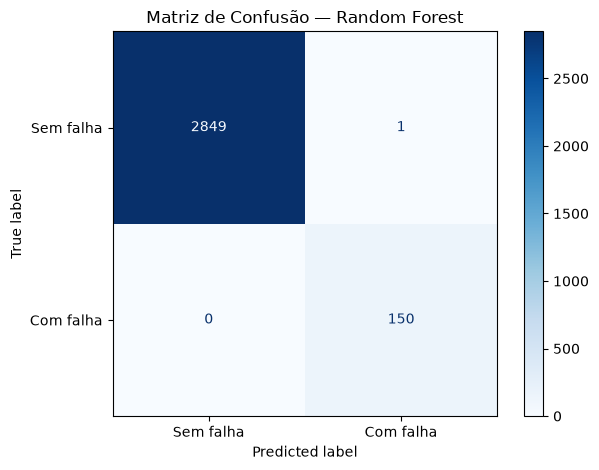

In [59]:
y_pred_floresta = modelo_floresta.predict(X_teste)

print("Acurácia:", round(accuracy_score(y_teste, y_pred_floresta), 4))
print("Precisão:", round(precision_score(y_teste, y_pred_floresta, zero_division=0), 4))
print("Recall:", round(recall_score(y_teste, y_pred_floresta, zero_division=0), 4))
print("F1-score:", round(f1_score(y_teste, y_pred_floresta, zero_division=0), 4))

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    y_pred_floresta,
    target_names=["Sem falha", "Com falha"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    y_pred_floresta,
    display_labels=["Sem falha", "Com falha"],
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de Confusão — Random Forest")
plt.tight_layout()
plt.show()


In [60]:
resultados = pd.DataFrame([
    {
        "Modelo": "Regressão Logística",
        "Acurácia": accuracy_score(y_teste, y_pred_logistico),
        "Precisão": precision_score(y_teste, y_pred_logistico, zero_division=0),
        "Recall": recall_score(y_teste, y_pred_logistico, zero_division=0),
        "F1-score": f1_score(y_teste, y_pred_logistico, zero_division=0)
    },
    {
        "Modelo": "Random Forest",
        "Acurácia": accuracy_score(y_teste, y_pred_floresta),
        "Precisão": precision_score(y_teste, y_pred_floresta, zero_division=0),
        "Recall": recall_score(y_teste, y_pred_floresta, zero_division=0),
        "F1-score": f1_score(y_teste, y_pred_floresta, zero_division=0)
    }
])

display(resultados.round(4))


,Modelo,Acurácia,Precisão,Recall,F1-score
0,Regressão Logística,0.9977,0.9554,1.0,0.9772
1,Random Forest,0.9997,0.9934,1.0,0.9967


In [61]:
from sklearn.cluster import KMeans

# Preparação dos sensores sem utilizar falha_motor
preparador_kmeans = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("escalonamento", StandardScaler())
])

# Ajustar o preparo somente no conjunto de treino
X_treino_kmeans = preparador_kmeans.fit_transform(X_treino)
X_teste_kmeans = preparador_kmeans.transform(X_teste)

# Treinar dois grupos operacionais
modelo_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

modelo_kmeans.fit(X_treino_kmeans)

# Atribuir cada registro de teste a um grupo
grupos_kmeans = modelo_kmeans.predict(X_teste_kmeans)

print("K-Means treinado.")
print("\nQuantidade de registros por grupo:")
display(pd.Series(grupos_kmeans).value_counts().sort_index())


K-Means treinado.

Quantidade de registros por grupo:


0    2852
1     148
Name: count, dtype: int64

In [ ]:
comparacao_grupos = pd.crosstab(
    pd.Series(grupos_kmeans, name="Grupo K-Means"),
    y_teste.reset_index(drop=True).rename("Falha real")
)

print("Grupos encontrados versus falhas reais:")
display(comparacao_grupos)

Grupos encontrados versus falhas reais:


Falha real,0,1
Grupo K-Means,,
0,2850,2
1,0,148


In [63]:
avaliacao_kmeans = pd.DataFrame({
    "grupo": grupos_kmeans,
    "falha_real": y_teste.to_numpy()
})

taxa_falha_grupo = (
    avaliacao_kmeans.groupby("grupo")["falha_real"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "registros",
        "sum": "falhas",
        "mean": "proporcao_falhas"
    })
)

taxa_falha_grupo["proporcao_falhas"] *= 100

display(taxa_falha_grupo.round(2))


,registros,falhas,proporcao_falhas
grupo,,,
0,2852,2,0.07
1,148,148,100.00


In [64]:
import joblib
from pathlib import Path

pasta_modelos = Path("models")
pasta_modelos.mkdir(exist_ok=True)

arquivo_modelo = pasta_modelos / "modelo_random_forest.joblib"

joblib.dump(modelo_floresta, arquivo_modelo)

print(f"Modelo salvo em: {arquivo_modelo.resolve()}")

Modelo salvo em: C:\Users\ryhan_Schutz.EDU_FIESC\Documents\atividades_fabiano\atividade_pratica_doit_15_10\models\modelo_random_forest.joblib


In [65]:
resultados = pd.DataFrame([
    {
        "modelo": "Regressão Logística",
        "acuracia": accuracy_score(y_teste, y_pred_logistico),
        "precisao": precision_score(y_teste, y_pred_logistico),
        "recall": recall_score(y_teste, y_pred_logistico),
        "f1_score": f1_score(y_teste, y_pred_logistico)
    },
    {
        "modelo": "Random Forest",
        "acuracia": accuracy_score(y_teste, y_pred_floresta),
        "precisao": precision_score(y_teste, y_pred_floresta),
        "recall": recall_score(y_teste, y_pred_floresta),
        "f1_score": f1_score(y_teste, y_pred_floresta)
    }
])

display(resultados.round(4))

arquivo_resultados = Path("data") / "resultados_modelos.csv"
arquivo_resultados.parent.mkdir(exist_ok=True)

resultados.to_csv(arquivo_resultados, index=False)

print(f"\nResultados salvos em: {arquivo_resultados.resolve()}")

,modelo,acuracia,precisao,recall,f1_score
0,Regressão Logística,0.9977,0.9554,1.0,0.9772
1,Random Forest,0.9997,0.9934,1.0,0.9967



Resultados salvos em: C:\Users\ryhan_Schutz.EDU_FIESC\Documents\atividades_fabiano\atividade_pratica_doit_15_10\data\resultados_modelos.csv
